| **Name** | **Family Name** | **Matriculation Number** |
| -------- | --------------- | ------------------------ |
| Marco    | Lorenzato       | 2197529                  |
| Kevin    | Brugnera        | 2196578                  |
| Nicolò   | Teneggi         | 2195476                  |
| Polina   | Gridiaeva       | 2186171                  |


# Gradient descent & Deep Neural Networks, DNNs

Analyze the labeled data introduced in the lesson on DNNs. Consider samples with L=8 values. 
Use a network with 3 layers, each with 20 units.

## 1. Random search of best hyperparameters

Implement a “random search,” with the `keras_tuner` package; see [https://keras.io/guides/keras_tuner/getting_started/](https://keras.io/guides/keras_tuner/getting_started/)  
to improve the performace of the DNN by a random search in the hyperparameters’ space of the values that give the best accuracy of the validation data set.  

### Hyperparameters that could be considered for tuning include:  
- **Minimizer**: ADAM, RMSprop, Nesterov, ...  
- **Learning rate**: 10⁻⁶, 10⁻⁵, 10⁻⁴, 10⁻³, 10⁻², 10⁻¹  
- **Nonlinear activations**: sigmoid, ReLU, ELU, ...  
- **Dropout values**: 0, 0.1, 0.2  

### Analysis / Questions
Which conclusions can you draw by comparing the accuracy in the various cases?  
To answer this question, consider performing a **cross-validation** for results with similar accuracy.

In [ ]:
import numpy as np
import pandas as pd

from keras.models import Sequential
from keras.layers import Dense, Dropout, Input
from keras import optimizers
import keras_tuner
from keras.callbacks import EarlyStopping

import os
import matplotlib as mpl
import matplotlib.pyplot as plt

# default font
plt.rcParams['font.size'] = 13

from sklearn.preprocessing import StandardScaler

%run useful.py

# training/validation/test fractions
perc_train = 0.7
perc_valid = 0.15
perc_test = 0.15
#  check it sums to 1 
assert abs(perc_train + perc_valid + perc_test - 1.0) < 1e-12

# 1a. Reading the Data

As shown in the lecture notebook, we read the data by specifying `TYPE=4`.

(12000, 8)
8
[1.83918812 2.04560279 5.67725029 5.95544703 9.6451452  6.53177097
 7.48906638 6.53569871] 0
[7.47714809 9.61306736 0.08388298 1.06444377 2.98703714 6.56411183
 8.09812553 8.72175914] 0
[9.64647597 7.23685347 6.42475328 7.17453621 4.67599007 3.25584678
 4.39644606 7.29689083] 0
[9.94014586 6.76873712 7.90822518 1.70914258 0.26849276 8.00370244
 9.03722538 0.2467621 ] 0
[4.91747318 5.26255167 5.9636601  0.51957545 8.95089528 7.2826618
 8.18350011 5.00222753] 1
data: 12000
train: 8400
valid: 1800
test: 1800


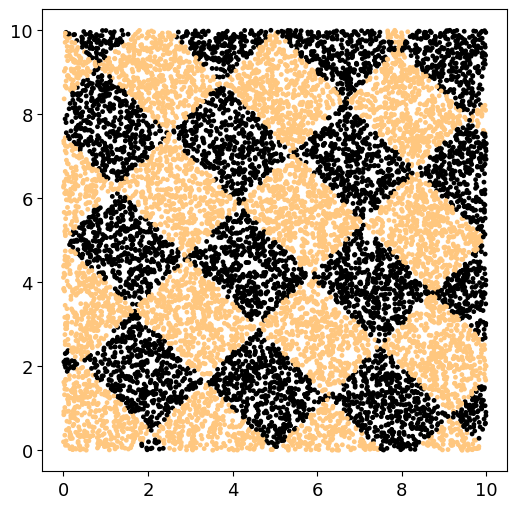

In [2]:
# Keras works with numpy arrays: just use them from the start

TYPE=4
# number of features per sample
L=8
# span of each component
B=10
x = np.loadtxt(filename("data",L,TYPE), delimiter=' ')
y = np.loadtxt(filename("labels",L,TYPE), delimiter=' ')
y = y.astype("int")
print(x.shape)
N = len(x)


# dim. of a sample
L = len(x[0])
print(L)

for i in range(5):
    print(x[i],y[i])

N_train = int(perc_train * N)
N_valid = int(perc_valid * N)
N_test = N - N_train - N_valid
print(f'data: {N}\ntrain: {N_train}\nvalid: {N_valid}\ntest: {N_test}')

plot_data(x,y)

### 1b. Split data and standardize

In [3]:
def Standardize(x,m,s):
    """
    rescale each component using its mean and standard deviation
    x: data points (numpy array)
    m: mean values (numpy array)
    s: standard deviations (numpy array)
    return: rescaled data points (numpy array)
    """
    N = len(x)
    # assuming len(m)=len(s)=len(x[0])
    mm,ss = np.tile(m,(N,1)), np.tile(s,(N,1))
    return (x-mm)/ss

# split data into train/validation/test sets and check 
(x_train, y_train) = (x[0:N_train],y[0:N_train])
(x_valid, y_valid) = (x[N_train:N_train+N_valid],y[N_train:N_train+N_valid])
(x_test, y_test) = (x[N_train+N_valid:],y[N_train+N_valid:])
print("Train:",len(x_train),"\t Validation:",len(x_valid),"\t Test:",len(x_test))


x_train_mean = np.mean(x_train, axis=0)
x_train_std = np.std(x_train, axis=0)
#print("train stats before rescaling:\nmean value=", x_train_mean, "\nstd. dev.=", x_train_std)

x_valid_mean = np.mean(x_valid, axis=0)
x_valid_std = np.std(x_valid, axis=0)
#print("validation stats before rescaling:\nmean value=", x_valid_mean, "\nstd. dev.=", x_valid_std)

x_test_mean = np.mean(x_test, axis=0)
x_test_std = np.std(x_test, axis=0)
#print("test stats before rescaling:\nmean value=", x_test_mean, "\nstd. dev.=", x_test_std)

x_train = Standardize(x_train, x_train_mean, x_train_std)
x_valid = Standardize(x_valid, x_valid_mean, x_valid_std)
x_test = Standardize(x_test, x_test_mean, x_test_std)
print("after rescaling (train):\nmean value=", x_train.mean(axis=0), "\nstd. dev.=", x_train.std(axis=0))

Train: 8400 	 Validation: 1800 	 Test: 1800
after rescaling (train):
mean value= [ 9.17572896e-16  1.18834043e-14 -1.95478554e-15 -3.53337069e-15
 -6.42594443e-15 -2.40365928e-15 -2.88332932e-15 -8.27623684e-15] 
std. dev.= [1. 1. 1. 1. 1. 1. 1. 1.]


### 1c. Random Search

In this step, we build the model with the specified architecture and implement the `RandomSearch` hyperparameter optimization method.  
The agent will test 30 different combinations of hyperparameters to tune the model and identify the best combination.  
Each combination is trained for 200 epochs.

In [4]:
def build_model(hp):
    model = Sequential()
    act = hp.Choice('activation', ['relu', 'elu', 'sigmoid', 'tanh'])
    opt_name = hp.Choice('optimizer', values=['adam', 'sgd', 'rmsprop'])
    lr = hp.Choice('learning_rate', values=[1e-4, 1e-3, 1e-2, 1e-1])
    drop = hp.Choice('dropout', values=[0.0, 0.1, 0.2])

    model.add(Input(shape=(L,)))
    model.add(Dense(L, activation=act))
    model.add(Dense(20, activation=act))
    model.add(Dropout(drop))
    model.add(Dense(20, activation=act))
    model.add(Dropout(drop))
    model.add(Dense(20, activation=act))
    model.add(Dropout(drop))
    model.add(Dense(1, activation='sigmoid'))
    
    opt = optimizers.get(opt_name)
    opt.learning_rate = lr

    model.compile(optimizer=opt, 
                  loss='binary_crossentropy', 
                  metrics=['accuracy'])
    return model

stop_early = EarlyStopping(monitor='val_loss', patience=10, min_delta=0.0005)

tuner = keras_tuner.RandomSearch(
    hypermodel=build_model,
    objective="val_loss",
    max_trials=30,
    executions_per_trial=1,
    overwrite=True,
    directory='./RandomSearch',
    project_name='randomSearchResults'
)

tuner.search(x_train, y_train, 
             epochs=200, batch_size = 200,
             validation_data=(x_valid, y_valid),
             callbacks=[stop_early])

models = tuner.get_best_models(num_models=4)
tuner.results_summary(num_trials=4)

Trial 30 Complete [00h 00m 04s]
val_loss: 0.6916710138320923

Best val_loss So Far: 0.13708098232746124
Total elapsed time: 00h 04m 15s


/home/ubuntu/LaboratoryOfComputationalPhysics_mod_B/LCP/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/home/ubuntu/LaboratoryOfComputationalPhysics_mod_B/LCP/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 2 variables whereas the saved optimizer has 12 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Results summary
Results in ./RandomSearch/randomSearchResults
Showing 4 best trials
Objective(name="val_loss", direction="min")

Trial 12 summary
Hyperparameters:
activation: elu
optimizer: adam
learning_rate: 0.01
dropout: 0.0
Score: 0.13708098232746124

Trial 13 summary
Hyperparameters:
activation: relu
optimizer: rmsprop
learning_rate: 0.01
dropout: 0.1
Score: 0.4842970669269562

Trial 02 summary
Hyperparameters:
activation: sigmoid
optimizer: rmsprop
learning_rate: 0.01
dropout: 0.0
Score: 0.5685389637947083

Trial 09 summary
Hyperparameters:
activation: elu
optimizer: rmsprop
learning_rate: 0.001
dropout: 0.0
Score: 0.670628011226654


### 1d. K-Fold Cross Validation

After saving the best 4 models selected by `RandomSearch`, we implemented a K-Fold cross-validation with $k = 4$.  
This allows us to select the best model for our training set, taking into account more than just the validation loss used in RandomSearch.

In [5]:
def k_fold_cross_validation(x_train, y_train, n_models: int, k: int, nepoch: int, batch_size: int = 50):

    np.random.seed(123)
    best_perf = 1e20
    best_model = None
    best_hps = None

    hps_list = tuner.get_best_hyperparameters(num_trials=n_models)

    # Fold idxs
    indices = np.arange(len(x_train))
    np.random.shuffle(indices)
    fold_size = len(x_train) // k

    x_folds = []
    y_folds = []
    for i in range(k):
        fold_idx = indices[i * fold_size: (i + 1) * fold_size]
        x_folds.append(x_train[fold_idx])
        y_folds.append(y_train[fold_idx])

    for hps in hps_list:
        model_perf = 0

        for test_idx in range(k):
            model = tuner.hypermodel.build(hps)            
            # Training folds
            x_train_fold = np.concatenate([x for i, x in enumerate(x_folds) if i != test_idx])
            y_train_fold = np.concatenate([y for i, y in enumerate(y_folds) if i != test_idx])
            # Validation fold
            x_val_fold = x_folds[test_idx]
            y_val_fold = y_folds[test_idx]
            # fit and save the score
            fit = model.fit(x_train_fold, y_train_fold,
                            validation_data=(x_val_fold, y_val_fold),
                            epochs=nepoch, batch_size=batch_size, verbose=1)
            model_perf += fit.history['val_loss'][-1]
        model_perf /= k

        if model_perf < best_perf:
            best_perf = model_perf
            best_model = model
            best_hps = hps
            
    return best_hps

In [ ]:
best_hps = k_fold_cross_validation(x_train, y_train, n_models=2, k=4, nepoch=100, batch_size=200)

### 1e. Training

In this step, we train the best model selected through K-Fold Cross-Validation.

In [ ]:
best_model = tuner.hypermodel.build(best_hps)

fit = best_model.fit(
    x_train, y_train,
    epochs=500, 
    batch_size=200,
    validation_data=(x_valid, y_valid),
    verbose=1
)

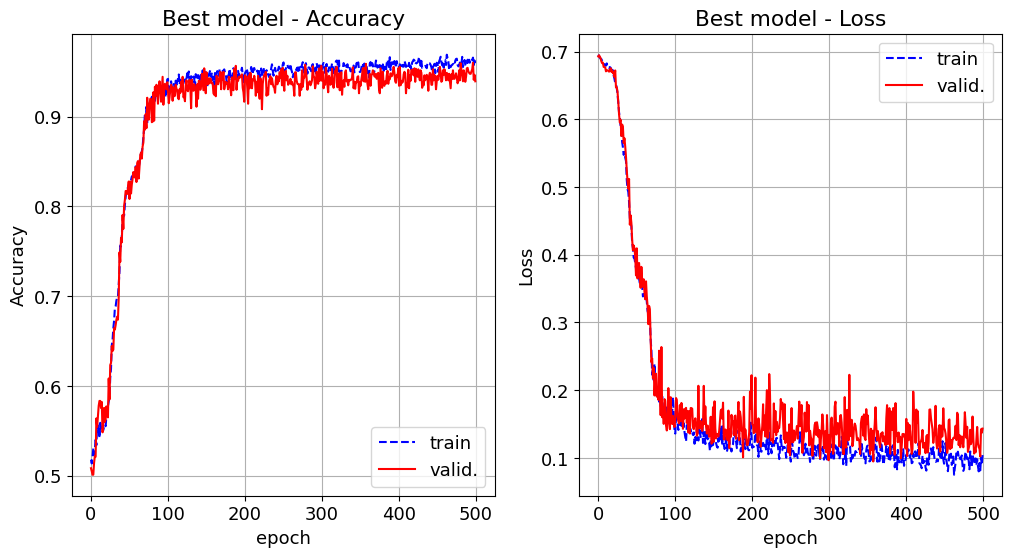

In [8]:
fig,AX=plt.subplots(1,2,figsize=(12,6))

ax=AX[0]
ax.plot(fit.history['accuracy'],label="train",c="b",ls="--")
ax.plot(fit.history['val_accuracy'],label="valid.",c="r")
ax.set_title('Best model - Accuracy')
ax.set_xlabel('epoch')
ax.set_ylabel("Accuracy")
ax.legend()
ax.grid()
ax=AX[1]
ax.plot(fit.history['loss'],label="train",c="b",ls="--")
ax.plot(fit.history['val_loss'],label="valid.",c="r")
ax.set_title('Best model - Loss')
ax.set_xlabel('epoch')
ax.set_ylabel("Loss")
ax.legend()
ax.grid()
plt.show()

### 1f. Evaluation on the test set

In [9]:
test_loss, test_acc = best_model.evaluate(x_test, y_test, verbose=0)
print(f"Final test loss: {test_loss:.4f}")
print(f"Final test accuracy: {test_acc:.4f}")

Final test loss: 0.2257
Final test accuracy: 0.9194


### 1g. Grid to show predictions

319/319 ━━━━━━━━━━━━━━━━━━━━ 0s 834us/step


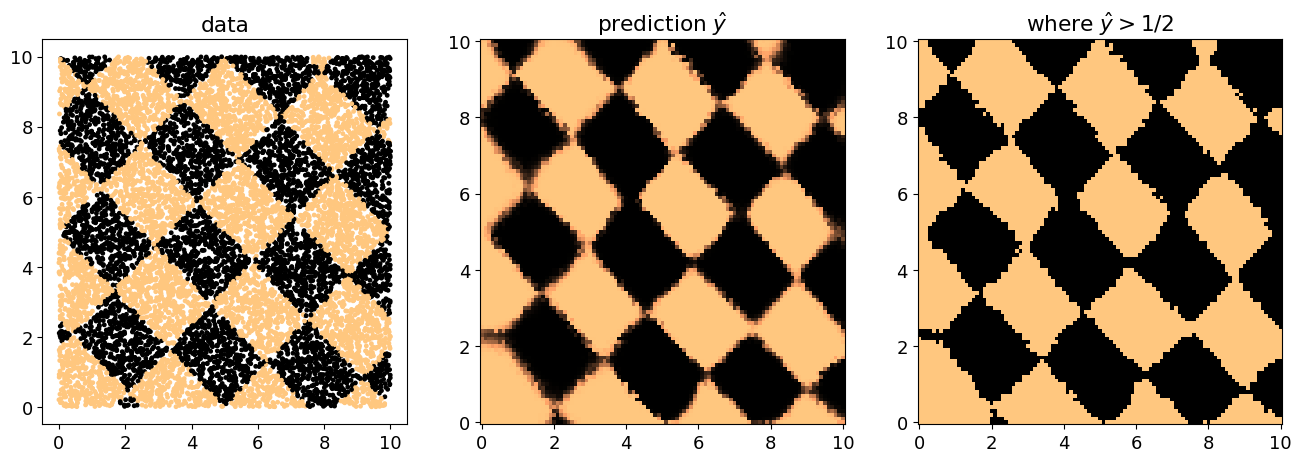

In [10]:
dX = .1
X1 = np.arange(0,10+dX, dX)
LG = len(X1)
# 2D meshgrid
X, Y = np.meshgrid(X1, X1)
allXY = np.reshape((np.array((X,Y)).T),(LG**2,2))
#create synthetic inputs with L features for each grid point; initialized randomly in [0, B].
grid = np.random.rand(LG**2,L)*B
#replace first 2 features with the actual 2D coordinates
grid[:,:2] = allXY
#standardize using train-set mean/std before prediction
grid_r=Standardize(grid,x_train_mean,x_train_std)

pred = best_model.predict(grid_r)

fig,AX=plt.subplots(1,3,figsize=(16,5.))
ax=AX[0]
ax.scatter(x[:,0],x[:,1],c=y,s=6)
ax.set_title("data")
ax=AX[1]
ax.pcolormesh(X1,X1,pred.reshape((LG, LG)))
ax.set_title("prediction $\\hat y$")
ax=AX[2]
pred01=np.copy(pred)
pred01[pred>0.5]=1
pred01[pred<=0.5]=0
ax.pcolormesh(X1,X1,pred01.reshape((LG, LG)))
ax.set_title("where $\\hat y > 1/2$")
plt.show()

After training the best model, we evaluated it using the loss curve and accuracy curve.  
We also verified its performance with a grid plot, confirming that the model predicts our dataset well.  
In particular, this model proved to be the best among those previously selected by RandomSearch (other results are not shown for clarity).

## 2. Data reduction / augmentation

Take a DNN with good parameters from point 1 and study how its performance changes when the number N of samples is:  

a) reduced  
b) augmented  

Point 2.b means taking the original N samples, splitting them in training and validation, and “augmenting” the training samples by generating artificial ones similar to the real ones. For example, one could add some random, small fluctuations to a training sample to generate a new one.

### 2a. Data Reduction

We implemented a function called `data_reduction` that, given a specified fraction of the original dataset, returns a reduced subset accordingly.

In [11]:
# specify the fraction of the initial dataset that we want to consider
fraction = 0.75  # between 0 and 1

# number of reduced data
Nred = int(x.shape[0] * fraction)

def data_reduction(x, y, N_red):

    # chosen points
    idx_red = np.random.randint(0, x.shape[0], size=N_red)
    x_red = x[idx_red].copy()
    y_red = y[idx_red].copy()

    return x_red, y_red

xred, yred = data_reduction(x, y, Nred)
print(f"Reduced Dataset size (- {(1 - fraction) * 100} %): \n ", xred.shape, yred.shape)

Reduced Dataset size (- 25.0 %): 
  (9000, 8) (9000,)


After that, we split the dataset into training, validation, and test sets, as done previously, and we train the `model_final`—obtained in Section 1 via RandomSearch and Cross-Validation—on this reduced dataset.

In [12]:
Nred_train = int(perc_train * Nred)
Nred_valid = int(perc_valid * Nred)
Nred_test = Nred - Nred_train - Nred_valid

print(f'data: {Nred}\ntrain: {Nred_train}\nvalid: {Nred_valid}\ntest: {Nred_test}')

# split data into train/validation/test sets
(xred_train, yred_train) = (xred[0:Nred_train], yred[0:Nred_train])
(xred_valid, yred_valid) = (xred[Nred_train:Nred_train+Nred_valid], yred[Nred_train:Nred_train+Nred_valid])
(xred_test, yred_test) = (xred[Nred_train+Nred_valid:], yred[Nred_train+Nred_valid:])

# statistics before scaling
xred_train_mean = np.mean(xred_train, axis=0)
xred_train_std = np.std(xred_train, axis=0)

xred_valid_mean = np.mean(xred_valid, axis=0)
xred_valid_std = np.std(xred_valid, axis=0)

xred_test_mean = np.mean(xred_test, axis=0)
xred_test_std = np.std(xred_test, axis=0)

# standardization
xred_train = Standardize(xred_train, xred_train_mean, xred_train_std)
xred_valid = Standardize(xred_valid, xred_valid_mean, xred_valid_std)
xred_test = Standardize(xred_test, xred_test_mean, xred_test_std)

data: 9000
train: 6300
valid: 1350
test: 1350


In [ ]:
# train best previous model and check results

model_final = tuner.hypermodel.build(best_hps)

# we now fit in using reduced dataset
red_fit = model_final.fit(xred_train, yred_train, epochs=500, batch_size=200, validation_data=(xred_valid, yred_valid), verbose=1)

To visualize the results and make comparisons, we reproduce the same plots as generated previously.

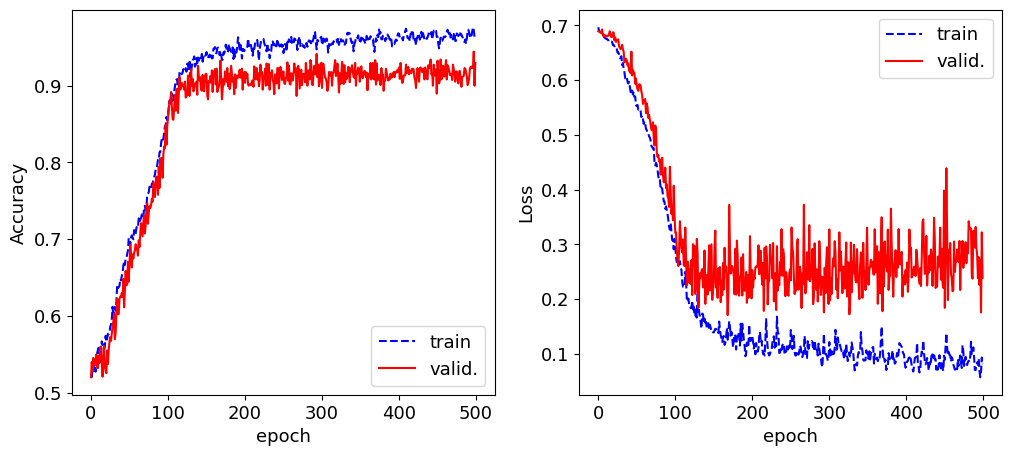

In [14]:
fig,AX=plt.subplots(1,2,figsize=(12,5.))
ax=AX[0]
ax.plot(red_fit.history['accuracy'],label="train",c="b",ls="--")
ax.plot(red_fit.history['val_accuracy'],label="valid.",c="r")
ax.set_xlabel('epoch')
ax.set_ylabel("Accuracy")
ax.legend()
ax=AX[1]
ax.plot(red_fit.history['loss'],label="train",c="b",ls="--")
ax.plot(red_fit.history['val_loss'],label="valid.",c="r")
ax.set_xlabel('epoch')
ax.set_ylabel("Loss")
ax.legend()

We also evaluated the model on the reduced test set to assess its performance on unseen data.

In [15]:
test_red_loss, test_red_acc = model_final.evaluate(xred_test, yred_test, verbose=0)
print(f"Final test loss: {test_red_loss:.4f}")
print(f"Final test accuracy: {test_red_acc:.4f}")

Final test loss: 0.3466
Final test accuracy: 0.9119


319/319 ━━━━━━━━━━━━━━━━━━━━ 0s 862us/step


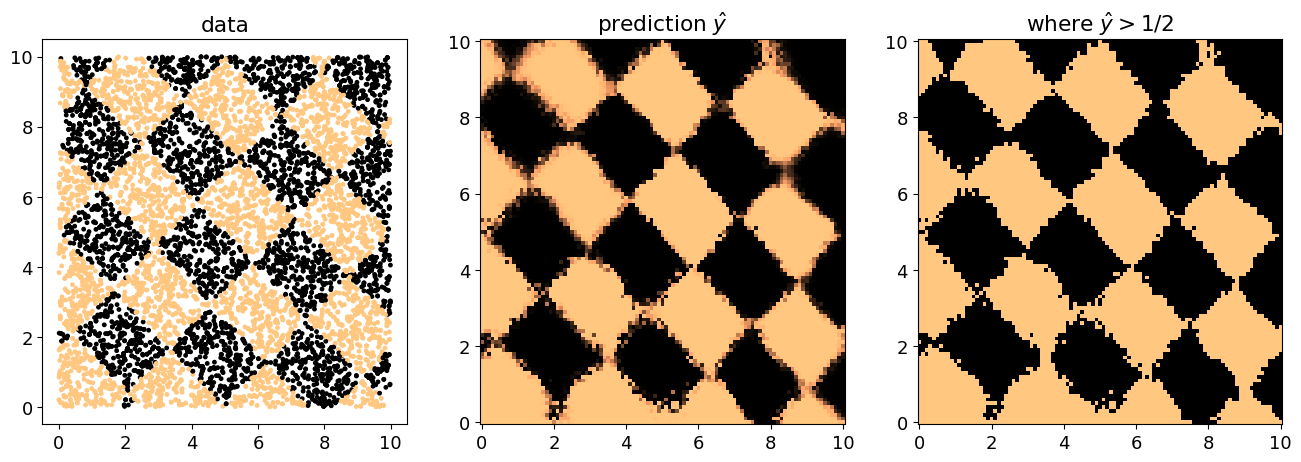

In [16]:
dX = .1
X1 = np.arange(0,10+dX, dX)
LG = len(X1)
# 2D meshgrid
X, Y = np.meshgrid(X1, X1)
allXY = np.reshape((np.array((X,Y)).T),(LG**2,2))
#create synthetic inputs with L features for each grid point; initialized randomly in [0, B].
grid = np.random.rand(LG**2,L)*B
#replace first 2 features with the actual 2D coordinates
grid[:,:2] = allXY
#standardize using train-set mean/std before prediction
grid_r=Standardize(grid,xred_train_mean,xred_train_std)

pred = model_final.predict(grid_r)

fig,AX=plt.subplots(1,3,figsize=(16,5.))
ax=AX[0]
ax.scatter(xred[:,0],xred[:,1],c=yred,s=6)
ax.set_title("data")
ax=AX[1]
ax.pcolormesh(X1,X1,pred.reshape((LG, LG)))
ax.set_title("prediction $\\hat y$")
ax=AX[2]
pred01=np.copy(pred)
pred01[pred>0.5]=1
pred01[pred<=0.5]=0
ax.pcolormesh(X1,X1,pred01.reshape((LG, LG)))
ax.set_title("where $\\hat y > 1/2$")
plt.show()

We can conclude that the model performs well even with the reduced training set.  
However, compared to Section 1, using less data leads to slightly lower learning performance.  
The results remain consistent but are somewhat worse than before, particularly with a higher test loss.

### 2b. Data Augmentation

We implemented a function called `data_augmentation` that takes the initial training set and augments it by a specified `fraction`.  
The augmentation is performed by selecting each new sample from a point in the original training set and adding Gaussian noise $\mathcal{N}(0,0.01)$.  
Clipping is applied to rescale the new samples within the range $[0,10]^2$, accepting that the boundaries may become slightly more populated.

In [17]:
def data_augmentation(x_train, y_train, fraction):  # augment only initial training set

    Naug = int(x_train.shape[0] * (1 + fraction))  
    xaug_train, yaug_train = np.zeros((Naug, x_train.shape[1])), np.zeros(Naug)
    xaug_train[:x_train.shape[0], :] = x_train
    yaug_train[:x_train.shape[0]] = y_train

    for i in range(x_train.shape[0], Naug):

        idx = np.random.randint(0, x_train.shape[0])
        xaug_train[i, :] = np.clip(x_train[idx, :] + np.random.normal(loc=0.0, scale=0.1, size=x_train.shape[1]), 0, 10) # rescaled in (0, 10)
        yaug_train[i] = NF(xaug_train[i, :],B,TYPE) # using previous labeling function

    return xaug_train, yaug_train # not yet standardized

In [18]:
fraction = 0.5 

# split data into train/validation/test sets and check 
(x_train, y_train) = (x[0:N_train],y[0:N_train])
(x_valid, y_valid) = (x[N_train:N_train+N_valid],y[N_train:N_train+N_valid])
(x_test, y_test) = (x[N_train+N_valid:],y[N_train+N_valid:])
print("Initial Training set size: \n ", x_train.shape, y_train.shape)

xaug_train, yaug_train = data_augmentation(x_train, y_train, fraction)
print(f"Augmented Training set size (+ {fraction * 100} %): \n ", xaug_train.shape, yaug_train.shape)

xaug = np.vstack((x, xaug_train[x_train.shape[0]:, :]))    
yaug = np.hstack((y, yaug_train[y_train.shape[0]:])) # since it's 1D   
print("Augmented Dataset size: \n ", xaug.shape, yaug.shape)

Initial Training set size: 
  (8400, 8) (8400,)
Augmented Training set size (+ 50.0 %): 
  (12600, 8) (12600,)
Augmented Dataset size: 
  (16200, 8) (16200,)


After that, we split the dataset into training, validation, and test sets, as done previously, and we train the `model_final`—obtained in Section 1 via RandomSearch and Cross-Validation—on this augmented dataset.

In [ ]:
#standardize agumented training set before training
xaug_train = Standardize(xaug_train, np.mean(xaug_train, axis=0), np.std(xaug_train, axis=0))
x_valid = Standardize(x_valid, np.mean(x_valid, axis=0), np.std(x_valid, axis=0))
x_test = Standardize(x_test, np.mean(x_test, axis=0), np.std(x_test, axis=0))


model_final_aug = tuner.hypermodel.build(best_hps)

# we now fit in using reduced dataset
aug_fit = model_final_aug.fit(xaug_train, yaug_train, epochs=500, batch_size=200, validation_data=(x_valid, y_valid), verbose=1)

To visualize the results and make comparisons, we reproduce the same plots as generated previously.

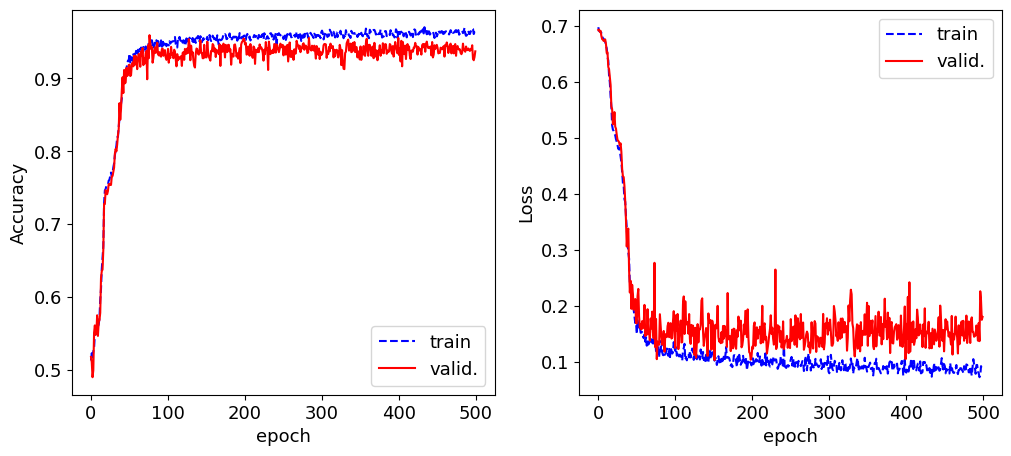

In [20]:
fig,AX=plt.subplots(1,2,figsize=(12,5.))
ax=AX[0]
ax.plot(aug_fit.history['accuracy'],label="train",c="b",ls="--")
ax.plot(aug_fit.history['val_accuracy'],label="valid.",c="r")
ax.set_xlabel('epoch')
ax.set_ylabel("Accuracy")
ax.legend()
ax=AX[1]
ax.plot(aug_fit.history['loss'],label="train",c="b",ls="--")
ax.plot(aug_fit.history['val_loss'],label="valid.",c="r")
ax.set_xlabel('epoch')
ax.set_ylabel("Loss")
ax.legend()

In [21]:
test_aug_loss, test_aug_acc = model_final_aug.evaluate(x_test, y_test, verbose=0)
print(f"Final test loss: {test_aug_loss:.4f}")
print(f"Final test accuracy: {test_aug_acc:.4f}")

Final test loss: 0.2150
Final test accuracy: 0.9283


319/319 ━━━━━━━━━━━━━━━━━━━━ 0s 771us/step


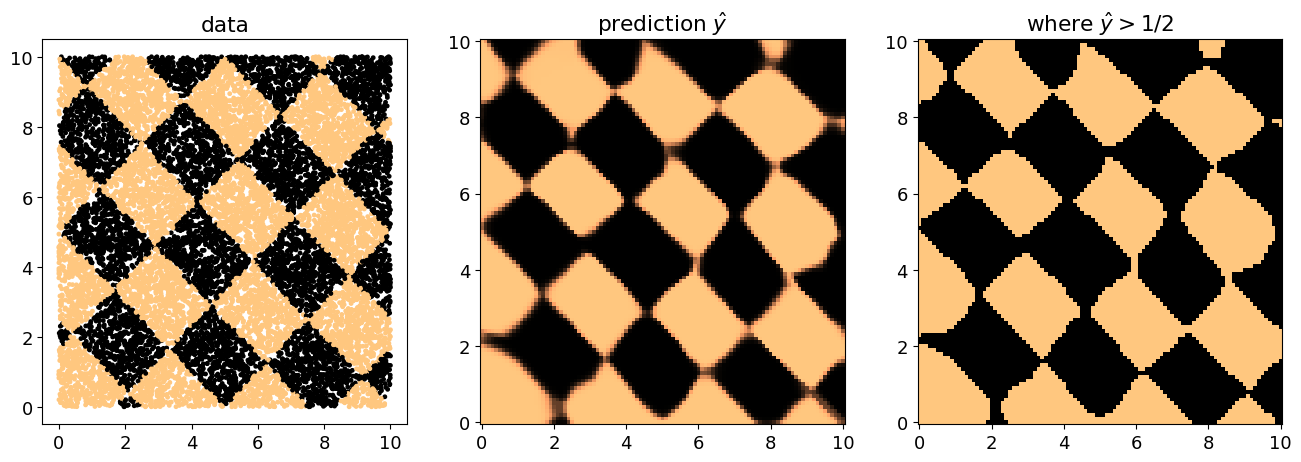

In [22]:
dX = .1
X1 = np.arange(0,10+dX, dX)
LG = len(X1)
# 2D meshgrid
X, Y = np.meshgrid(X1, X1)
allXY = np.reshape((np.array((X,Y)).T),(LG**2,2))
#create synthetic inputs with L features for each grid point; initialized randomly in [0, B].
grid = np.random.rand(LG**2,L)*B
#replace first 2 features with the actual 2D coordinates
grid[:,:2] = allXY
grid[:,2:] = 0
#standardize using train-set mean/std before prediction
grid_r = Standardize(grid, np.mean(x_train, axis=0), np.std(x_train, axis=0))

pred = model_final_aug.predict(grid_r)

fig,AX=plt.subplots(1,3,figsize=(16,5.))
ax=AX[0]
ax.scatter(xaug[:,0],xaug[:,1],c=yaug,s=6)
ax.set_title("data")
ax=AX[1]
ax.pcolormesh(X1,X1,pred.reshape((LG, LG)))
ax.set_title("prediction $\\hat y$")
ax=AX[2]
pred01=np.copy(pred)
pred01[pred>0.5]=1
pred01[pred<=0.5]=0
ax.pcolormesh(X1,X1,pred01.reshape((LG, LG)))
ax.set_title("where $\\hat y > 1/2$")
plt.show()

We can conclude that the augmented dataset is the best for training the model selected previously.  
A larger dataset allows the model to generalize better and explore the sample space more thoroughly, effectively learning the label distribution.  
As a result, the test loss achieved is the lowest so far.  

However, the original dataset from Section 1 represents a better compromise in terms of computational time and cost.  
Although the results are slightly worse, the difference is not significant enough to justify a 50% increase in training set size.